# t-SNE: Mapping Digit Images in 2D

**Family:** Unsupervised learning | **Level:** Intermediate | **Dataset:** `digits` | **Runs on:** CPU, about 1 minute(s)

Embed high dimensional data so that neighbours stay neighbours.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- How t-SNE matches neighbour probabilities
- What perplexity means
- Why distances between clusters are not meaningful
- How to measure embedding quality

**Prerequisites:**

- Distances and vectors
- Standardising features

**Skills you will have afterwards:**

- Pick settings without labels
- Check stability
- Compare with a reference labelling

## 2. Real-World Problem

**Context.** Analysts want to look at high dimensional data in a plot.

**The problem.** Show the structure of 1797 digit images in two dimensions.

**Why it matters.** A good map reveals groups and mistakes before modelling.

**Why machine learning.** Raw pixels cannot be plotted.

**Why this algorithm.** t-SNE preserves local neighbourhoods better than PCA.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### Visualizing Data using t-SNE

- **Type:** foundational paper
- **Authors:** van der Maaten, L. and Hinton, G.
- **Year and venue:** 2008, Journal of Machine Learning Research 9:2579-2605
- **DOI or URL:** https://jmlr.org/papers/v9/vandermaaten08a.html
- **Verification:** not verified in build environment
- **Research objective:** Visualise high dimensional data in two or three dimensions.
- **Methodology:** Match neighbour probabilities with a Student t kernel in the map.
- **Dataset:** MNIST, Olivetti faces, COIL-20 and others.
- **Main findings:** Clearer cluster separation than earlier methods in the paper.
- **Limitations:** Global distances are not preserved. Hyperparameter sensitive.

**Relationship to this notebook.** van der Maaten and Hinton introduce t-SNE. That entry is not verified in the build environment, so check it before citing. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**High dimensional affinities.** $p_{j|i} = \dfrac{\exp(-\lVert x_i-x_j\rVert^2/2\sigma_i^2)}{\sum_{k\ne i}\exp(-\lVert x_i-x_k\rVert^2/2\sigma_i^2)}$ with $\sigma_i$ set so that the perplexity $2^{H(P_i)}$ matches the target. Then $p_{ij} = (p_{j|i}+p_{i|j})/2n$.

**Low dimensional affinities.** Student t with one degree of freedom: $q_{ij} = \dfrac{(1+\lVert y_i-y_j\rVert^2)^{-1}}{\sum_{k\ne l}(1+\lVert y_k-y_l\rVert^2)^{-1}}$.

**Objective.** Minimise $KL(P\Vert Q) = \sum_{i\ne j} p_{ij}\log(p_{ij}/q_{ij})$ by gradient descent.

**Limits.** Non convex, cluster sizes and gaps are not reliable, no out of sample transform.

## 5. Dataset Introduction

**Optical Recognition of Handwritten Digits**, UCI, licence CC BY 4.0, DOI 10.24432/C50P49. scikit-learn ships 1797 images (the test part of the UCI data) as 8 by 8 grids, so 64 integer pixel features from 0 to 16. Target `digit`, ten classes. Limit: far smaller than MNIST.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from ml_lab.data import load_dataset
from ml_lab.evaluation import internal_scores, external_scores
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "tsne"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

bundle = load_dataset("digits")
X_raw = bundle.X
y_true = bundle.y          # evaluation only
print("shape:", X_raw.shape)
display(pd.Series(bundle.describe_source(), name="source").to_frame())

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0
shape: (1797, 64)


,source
title,Optical Recognition of Handwritten Digits
source,UCI Machine Learning Repository
url,https://archive.ics.uci.edu/dataset/80/optical...
license,CC BY 4.0
doi,10.24432/C50P49
rows,1797
features,64
limits,"8x8 images, much smaller than MNIST."


## 6. Exploratory Data Analysis

We check size, missing values, label balance and feature relations. The reference labels are used for evaluation only, never for fitting. 

Rows and columns: (1797, 64)
Missing values: 0


,count,mean,std,min,25%,50%,75%,max
pixel_0_0,1797.0,0.000,0.000,0.0,0.0,0.0,0.0,0.0
pixel_0_1,1797.0,0.304,0.907,0.0,0.0,0.0,0.0,8.0
pixel_0_2,1797.0,5.205,4.755,0.0,1.0,4.0,9.0,16.0
pixel_0_3,1797.0,11.836,4.249,0.0,10.0,13.0,15.0,16.0
pixel_0_4,1797.0,11.848,4.287,0.0,10.0,13.0,15.0,16.0
pixel_0_5,1797.0,5.782,5.666,0.0,0.0,4.0,11.0,16.0
pixel_0_6,1797.0,1.362,3.326,0.0,0.0,0.0,0.0,16.0
pixel_0_7,1797.0,0.130,1.037,0.0,0.0,0.0,0.0,15.0
pixel_1_0,1797.0,0.006,0.094,0.0,0.0,0.0,0.0,2.0
pixel_1_1,1797.0,1.994,3.196,0.0,0.0,0.0,3.0,16.0


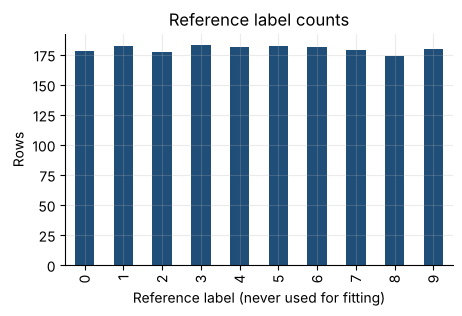

Mean absolute correlation between features: nan


In [2]:
print("Rows and columns:", X_raw.shape)
print("Missing values:", int(X_raw.isna().sum().sum()))
display(X_raw.describe().T.head(15).round(3))
fig, ax = plt.subplots(figsize=(5, 3))
pd.Series(y_true).value_counts().sort_index().plot.bar(ax=ax)
ax.set_xlabel("Reference label (never used for fitting)"); ax.set_ylabel("Rows"); ax.set_title("Reference label counts")
plt.show()
corr = X_raw.corr().abs().to_numpy(copy=True)
np.fill_diagonal(corr, 0)
print("Mean absolute correlation between features:", round(float(corr.mean()), 3))

## 7. Data Preprocessing

Pixels are scaled to 0 to 1 and projected to 30 components first, which is the usual practice to cut noise and run time.

In [3]:
X = PCA(30, random_state=SEED).fit_transform(X_raw.values / 16.0)
print(X.shape)

(1797, 30)


## 8. Algorithm Implementation

### 8.1 Concept

Neighbours in the original space should be neighbours in the map. A heavy tailed kernel in 2D lets clusters separate.

### 8.2 Python implementation from scratch

A short NumPy t-SNE on 300 rows with a fixed sigma search, 250 gradient steps, and no early exaggeration tricks beyond a simple one.

In [4]:
from sklearn.manifold import trustworthiness
def p_matrix(P, perplexity=30.0):
    n = len(P)
    D = ((P[:, None] - P[None]) ** 2).sum(axis=2)
    out = np.zeros((n, n))
    target = np.log(perplexity)
    for i in range(n):
        lo, hi, beta = 0.0, np.inf, 1.0
        for _ in range(50):
            pr = np.exp(-D[i] * beta); pr[i] = 0
            s = pr.sum() + 1e-12
            H = np.log(s) + beta * (D[i] * pr).sum() / s
            if H > target:
                lo = beta; beta = beta * 2 if hi == np.inf else (beta + hi) / 2
            else:
                hi = beta; beta = (beta + lo) / 2
        pr = np.exp(-D[i] * beta); pr[i] = 0
        out[i] = pr / pr.sum()
    return (out + out.T) / (2 * n)
sub = X[:300]
P = p_matrix(sub)
rng = np.random.default_rng(SEED)
Y = rng.normal(0, 1e-2, (300, 2)); vel = np.zeros_like(Y)
for it in range(250):
    d = ((Y[:, None] - Y[None]) ** 2).sum(axis=2)
    num = 1 / (1 + d); np.fill_diagonal(num, 0)
    Q = np.maximum(num / num.sum(), 1e-12)
    PQ = (4.0 if it < 50 else 1.0) * P - Q
    grad = 4 * ((PQ * num)[:, :, None] * (Y[:, None] - Y[None])).sum(axis=1)
    vel = (0.5 if it < 100 else 0.8) * vel - 100 * grad
    Y = Y + vel
print("trustworthiness of the scratch map (k=10):", round(float(trustworthiness(sub, Y, n_neighbors=10)), 3))

trustworthiness of the scratch map (k=10): 0.992


### 8.3 Library implementation

scikit-learn and scipy provide tested implementations.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `perplexity` | Effective number of neighbours, usually 5 to 50. |
| `learning_rate` | Step size. |
| `max_iter` | Optimisation steps. |
| `init` | `pca` is more stable than `random`. |

## 9. Model Training

We run t-SNE for perplexity 5, 15, 30 and 50 and choose by trustworthiness (share of neighbours that are kept, 1 is best). The reference digit is not used for the choice.

In [5]:
from sklearn.manifold import TSNE
embeds, rows = {}, []
for perp in [5, 15, 30, 50]:
    ts = TSNE(2, perplexity=perp, init="pca", random_state=SEED)
    emb = ts.fit_transform(X)
    embeds[perp] = emb
    rows.append({"perplexity": perp, "trustworthiness": trustworthiness(X, emb, n_neighbors=10), "kl_divergence": ts.kl_divergence_})
sweep = pd.DataFrame(rows).set_index("perplexity")
display(sweep.round(4))
BEST = int(sweep["trustworthiness"].idxmax())
emb = embeds[BEST]

,trustworthiness,kl_divergence
perplexity,,
5,0.9918,0.9336
15,0.9933,0.8477
30,0.9932,0.7444
50,0.9921,0.6702


## 10. Evaluation

Trustworthiness measures local structure. A 5-nearest-neighbour classifier trained on the embedding coordinates with cross validation shows whether the digit groups are separable in the map. This uses labels for evaluation only, and the embedding itself was fitted on all rows, so the number describes the map, not a prediction.

In [6]:
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
knn_acc = cross_val_score(KNeighborsClassifier(5), emb, y_true, cv=5).mean()
pca2 = PCA(2, random_state=SEED).fit_transform(X)
METRICS = {"trustworthiness": float(sweep.loc[BEST, "trustworthiness"]), "trustworthiness_pca2": float(trustworthiness(X, pca2, n_neighbors=10)),
           "knn_accuracy_in_map": float(knn_acc), "knn_accuracy_pca2": float(cross_val_score(KNeighborsClassifier(5), pca2, y_true, cv=5).mean())}
CONFIG = {"perplexity": BEST, "init": "pca", "pca_components": 30}
EXTRA = {"sweep": sweep.round(4).reset_index().to_dict("records")}

record = ExperimentRecord(notebook=NOTEBOOK_ID, family="unsupervised", algorithm="TSNE", dataset="digits",
                          task="clustering", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())
display(pd.Series(METRICS, name="metric").round(4).to_frame())

saved: experiments/results/tsne.json


,metric
trustworthiness,0.9933
trustworthiness_pca2,0.8320
knn_accuracy_in_map,0.9772
knn_accuracy_pca2,0.6032


## 11. Visualization

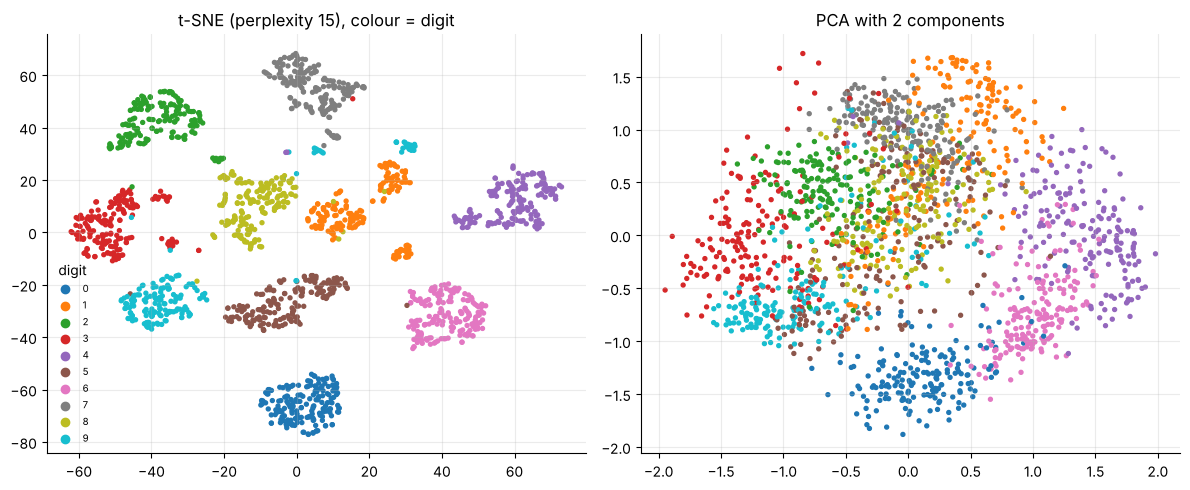

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sc = axes[0].scatter(emb[:, 0], emb[:, 1], c=y_true, cmap="tab10", s=8); axes[0].set_title(f"t-SNE (perplexity {BEST}), colour = digit")
axes[0].legend(*sc.legend_elements(), title="digit", loc="best", fontsize=7)
axes[1].scatter(pca2[:, 0], pca2[:, 1], c=y_true, cmap="tab10", s=8); axes[1].set_title("PCA with 2 components")
plt.tight_layout(); save_figure(fig, NOTEBOOK_ID, "overview"); plt.show()

## 12. Interpretation

Look for digits that sit between groups, and remember that gaps and sizes in the map are not reliable.

In [8]:
from sklearn.neighbors import NearestNeighbors
idx = NearestNeighbors(n_neighbors=6).fit(emb).kneighbors(emb)[1][:, 1:]
purity = (y_true.values[idx] == y_true.values[:, None]).mean(axis=1)
print("share of rows whose 5 map neighbours all share their digit:", round(float((purity == 1).mean()), 3))
print("digits with the lowest neighbour purity:", pd.Series(purity, index=y_true.values).groupby(level=0).mean().sort_values().head(3).round(3).to_dict())

share of rows whose 5 map neighbours all share their digit: 0.964
digits with the lowest neighbour purity: {9: 0.958, 8: 0.963, 1: 0.98}


## 13. Experiments and Challenges

### Experiment 1: Seed variability

Different seeds give different maps. Quality should be similar.

In [9]:
for s in range(3):
    e = TSNE(2, perplexity=BEST, init="random", random_state=s).fit_transform(X)
    print("seed", s, "trustworthiness", round(float(trustworthiness(X, e, n_neighbors=10)), 4))

seed 0 trustworthiness 0.9931


seed 1 trustworthiness 0.9919


seed 2 trustworthiness 0.9928


### Experiment 2: Random versus PCA initialisation

PCA init keeps global layout more stable.

In [10]:
for init in ["random", "pca"]:
    e = TSNE(2, perplexity=BEST, init=init, random_state=SEED).fit_transform(X)
    print(init, round(float(trustworthiness(X, e, n_neighbors=10)), 4))

random 0.9931


pca 0.9933


### Experiment 3: Distances between clusters

Distance between cluster centres in the map across perplexities. They change, so they carry no meaning.

In [11]:
for perp, e in embeds.items():
    c0, c1 = e[y_true == 0].mean(axis=0), e[y_true == 1].mean(axis=0)
    spread = e.std()
    print(f"perplexity {perp}: distance between centres of digit 0 and 1 divided by map spread = {np.linalg.norm(c0 - c1) / spread:.2f}")

perplexity 5: distance between centres of digit 0 and 1 divided by map spread = 2.41
perplexity 15: distance between centres of digit 0 and 1 divided by map spread = 2.20
perplexity 30: distance between centres of digit 0 and 1 divided by map spread = 2.68
perplexity 50: distance between centres of digit 0 and 1 divided by map spread = 2.81


### Exercises for learners

1. Repeat with `SEED = 7` and report which numbers move.
2. Change the number of rows by sampling 50 percent and compare the result.
3. Add pure noise columns and watch the internal scores.

## 14. Research Discussion

The original paper presents t-SNE as better than earlier methods at keeping local structure. The PCA comparison on trustworthiness checks that claim on digits only.

**Dataset and method differences.** The papers above use other data and protocols. We do not claim that our numbers agree or disagree with them. This notebook only shows whether the behaviour they describe appears on our data.

**Possible improvements.** Use openTSNE for out of sample transforms and report several seeds.

**Research limitations.** One dataset and one seed for the headline numbers. 

## 15. Summary and Further Reading

**Key takeaways**

- Perplexity sets the neighbourhood size.
- Do not read distances between clusters.
- Use trustworthiness to compare maps.

**Use cases.** Visualisation of embeddings, quality checks.

**Limitations.** No transform for new rows, non convex.

**Recommended next notebook.** UMAP.

**Further reading.** See `references.md` in this folder.